# Phân tích dữ liệu (EDA) và phân tích kết quả

Dữ liệu OHLCV từ Binance public API qua `ccxt` (chỉ dùng cho mục đích học tập). Notebook này trả lời 3 câu hỏi cho báo cáo:
1. Return của crypto có phân phối như thế nào?
2. Return có tự tương quan không, tức là có thể dự đoán được không?
3. Phí giao dịch ảnh hưởng tới chiến lược như thế nào?

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cq.data import load_ohlcv
from cq.features import build_features
from cq.labels import make_dataset
from cq.pipeline import load_config, run_all
cfg = load_config()
plt.rcParams['figure.figsize'] = (11, 4)
data = {s: load_ohlcv(s, '1d', cfg['since'], cfg['exchange']) for s in cfg['symbols']}
{s: (d.index[0].date(), d.index[-1].date(), len(d)) for s, d in data.items()}

{'BTC/USDT': (datetime.date(2019, 1, 1), datetime.date(2026, 11, 11), 2872),
 'ETH/USDT': (datetime.date(2019, 1, 1), datetime.date(2026, 11, 11), 2872),
 'SOL/USDT': (datetime.date(2020, 8, 11), datetime.date(2026, 11, 11), 2284)}

## 1. Giá và phân phối return

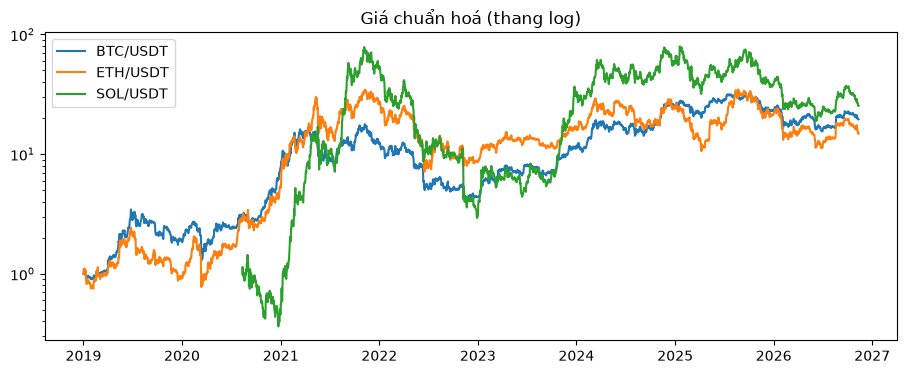

In [2]:
fig, ax = plt.subplots()
for s, d in data.items():
    ax.plot(d['close'] / d['close'].iloc[0], label=s)
ax.set_yscale('log'); ax.set_title('Giá chuẩn hoá (thang log)'); ax.legend(); plt.show()

In [3]:
rets = pd.DataFrame({s: np.log(d['close']).diff() for s, d in data.items()})
stats = pd.DataFrame({'mean': rets.mean(), 'std': rets.std(), 'skew': rets.skew(),
                      'kurtosis': rets.kurt(), 'up_rate': (rets > 0)[rets.notna()].mean()})
stats.round(4)

,mean,std,skew,kurtosis,up_rate
BTC/USDT,0.0010,0.0324,-1.2646,23.4285,0.509579
ETH/USDT,0.0009,0.0426,-1.0492,16.8174,0.514803
SOL/USDT,0.0014,0.0590,-0.2067,8.5349,0.496277


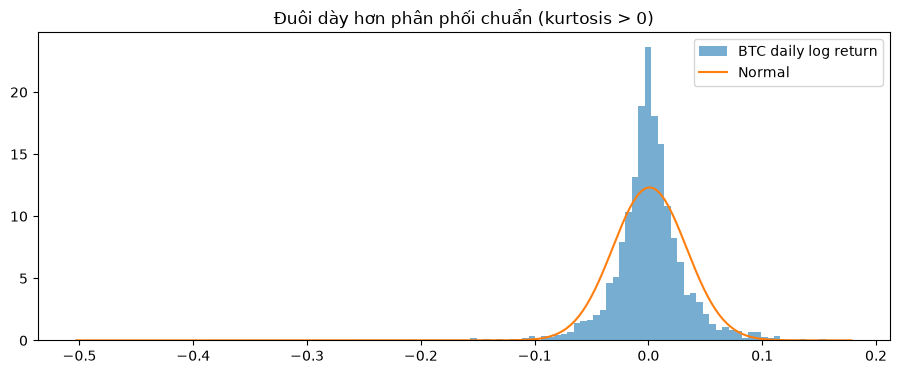

In [4]:
r = rets['BTC/USDT'].dropna()
x = np.linspace(r.min(), r.max(), 200)
plt.hist(r, bins=120, density=True, alpha=.6, label='BTC daily log return')
plt.plot(x, np.exp(-(x - r.mean())**2 / (2 * r.var())) / np.sqrt(2 * np.pi * r.var()), label='Normal')
plt.legend(); plt.title('Đuôi dày hơn phân phối chuẩn (kurtosis > 0)'); plt.show()

**Nhận xét:** tỷ lệ ngày tăng khoảng 50%, nên bài toán phân loại gần như cân bằng và accuracy 50% là mức ngẫu nhiên. Kurtosis lớn cho thấy có nhiều biến động cực đoan, đó là lý do các model rủi ro cao dễ bị drawdown lớn.

## 2. Tự tương quan

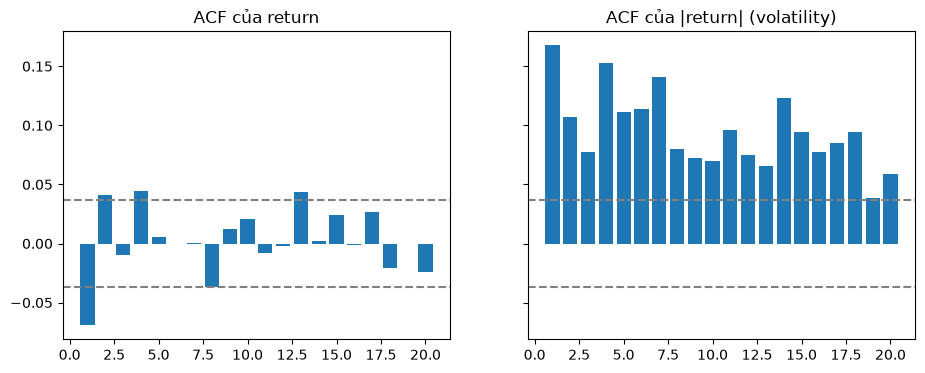

In [5]:
def acf(s, lags=20):
    return [s.autocorr(k) for k in range(1, lags + 1)]
fig, axes = plt.subplots(1, 2, sharey=True)
conf = 1.96 / np.sqrt(len(r))
for ax, series, title in ((axes[0], r, 'ACF của return'), (axes[1], r.abs(), 'ACF của |return| (volatility)')):
    ax.bar(range(1, 21), acf(series)); ax.axhline(conf, ls='--', c='gray'); ax.axhline(-conf, ls='--', c='gray')
    ax.set_title(title)
plt.show()

**Nhận xét:** tự tương quan của return gần như nằm trong dải tin cậy, tức hướng giá rất khó dự đoán (gần với giả thuyết thị trường hiệu quả). Ngược lại, |return| có tự tương quan rõ (volatility clustering), nên các feature về volatility có ích để biết lúc nào thị trường biến động mạnh.

## 3. Tương quan giữa feature và nhãn

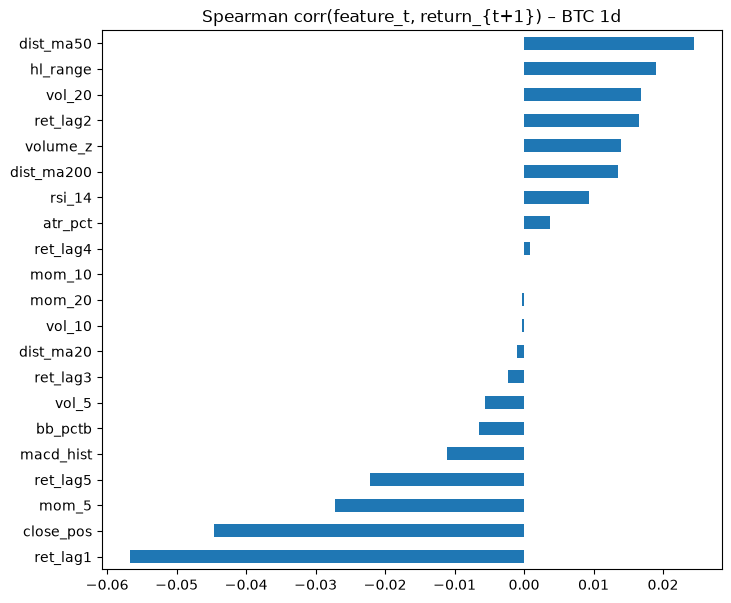

In [6]:
d = data['BTC/USDT']
X, y, fwd = make_dataset(build_features(d), d['close'])
X.corrwith(fwd, method='spearman').sort_values().plot.barh(figsize=(8, 7), title='Spearman corr(feature_t, return_{t+1}) – BTC 1d')
plt.show()

## 4. Kết quả walk-forward và tác động của phí

Khung 4h có accuracy cao hơn 1d, nhưng mô hình giao dịch rất nhiều lần. Ta so sánh kết quả với các mức phí khác nhau.

In [7]:
rows = []
for fee in [0.0, 0.0002, 0.0005, 0.001]:
    t, _ = run_all('BTC/USDT', '4h', cfg, threshold=0.5, fee=fee, models=['lightgbm'])
    rows.append({'fee_%': fee * 100, **t.loc['lightgbm', ['total_return', 'sharpe', 'max_drawdown', 'n_trades']].to_dict(),
                 'bh_return': t.loc['buy_and_hold', 'total_return']})
fee_tbl = pd.DataFrame(rows).set_index('fee_%'); fee_tbl.round(3)

,total_return,sharpe,max_drawdown,n_trades,bh_return
fee_%,,,,,
0.00,17.649,1.404,-0.525,5955.0,1.033
0.02,4.667,0.919,-0.585,5955.0,1.033
0.05,-0.051,0.192,-0.665,5955.0,1.033
0.10,-0.952,-1.020,-0.975,5955.0,1.033


In [8]:
t1d, exps = run_all('BTC/USDT', '1d', cfg, threshold='auto')
t1d.round(3)

,total_return,cagr,sharpe,max_drawdown,accuracy,auc,f1,up_rate,exposure,win_rate,n_trades
model,,,,,,,,,,,
buy_and_hold,1.400,0.179,0.577,-0.766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
baseline,1.398,0.179,0.576,-0.766,0.497,NaN,0.664,0.497,1.000,0.497,1.0
logreg,0.278,0.047,0.304,-0.366,0.514,0.520,0.518,0.497,0.187,0.522,354.0
lightgbm,-0.340,-0.075,-0.008,-0.691,0.520,0.523,0.540,0.497,0.525,0.499,658.0


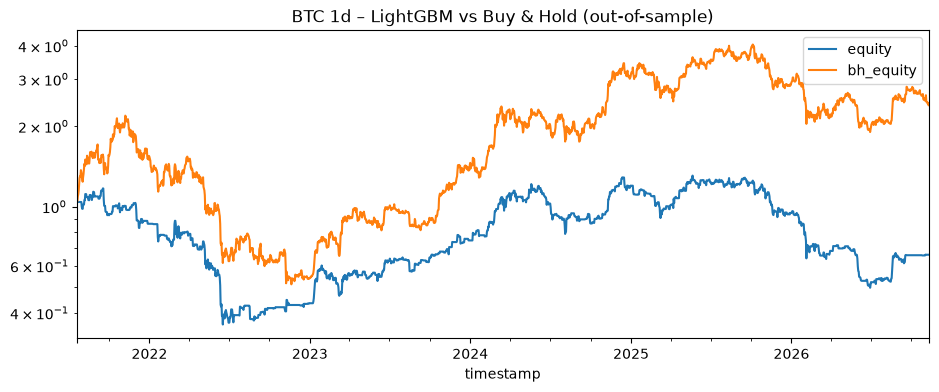

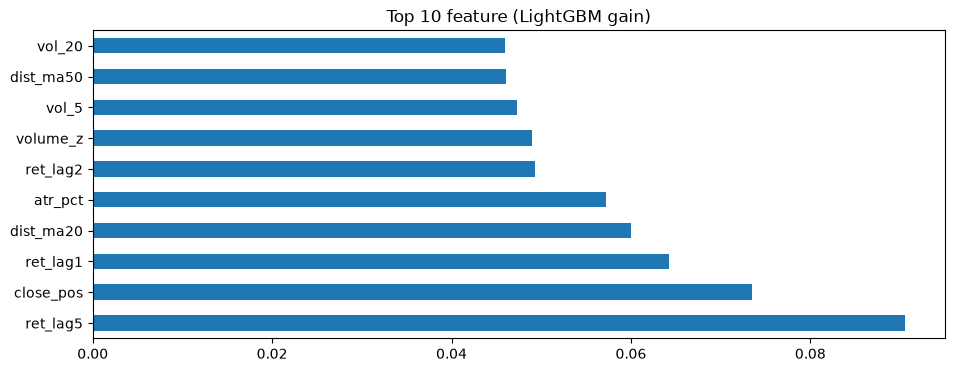

In [9]:
bt = exps['lightgbm'].bt
ax = bt[['equity', 'bh_equity']].plot(logy=True, title='BTC 1d – LightGBM vs Buy & Hold (out-of-sample)')
plt.show()
exps['lightgbm'].wf.importance.head(10).plot.barh(title='Top 10 feature (LightGBM gain)'); plt.show()

## Kết luận

- Accuracy out-of-sample chỉ đạt khoảng 50–55%, AUC khoảng 0.51–0.56: có tín hiệu nhưng rất yếu, và điều này đúng với kỳ vọng ở thị trường có tính cạnh tranh cao.
- Ở khung **4h** tín hiệu mạnh hơn và có lãi lớn khi **phí = 0**. Nhưng với phí thực tế 0.1%, hàng nghìn lần giao dịch ăn hết lợi nhuận. **Chi phí giao dịch là yếu tố quyết định** chiến lược có dùng được hay không.
- Ở khung **1d**, mô hình không thắng được Buy & Hold một cách ổn định giữa các coin. Một số cấu hình (ví dụ LogReg) giảm được drawdown nhưng đổi lại lợi nhuận thấp hơn.
- Hướng phát triển: giảm số lệnh (ngưỡng cao hơn, giữ vị thế tối thiểu N nến), đưa phí vào hàm mục tiêu, thêm dữ liệu on-chain hoặc funding rate.